# Research Assistant: разведочный анализ и BM25

Три ГОСТа по менеджменту качества. Проверяаем текст, дубликаты, облака слов и влияние разбиения на поиск. Данные и вопросы зафиксированы. Вопросы синтетические; проверки независимым человеком нет.

## 1. Окружение и запуск

In [1]:
from pathlib import Path
import sys, subprocess
REPO_REF = "main"
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
candidates = [Path.cwd(), Path.cwd().parent, Path('/content/research_assistant')]
REPO_ROOT = next((p for p in candidates if (p/'checkpoint_02/corpus.py').exists()), None)
if REPO_ROOT is None:
    REPO_ROOT = Path('/content/research_assistant') if IN_COLAB else Path.cwd()/'research_assistant'
    subprocess.run(['git','clone','--branch',REPO_REF,'https://github.com/eugenetatarchenkolaw/research_assistant.git',str(REPO_ROOT)], check=True)
if IN_COLAB:
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(REPO_ROOT/'checkpoint_02/requirements.txt')],check=True)
sys.path.insert(0,str(REPO_ROOT))
print(sys.version)
print(REPO_ROOT)


3.13.18 (main, Oct 26 2026, 14:19:33) [GCC 15.2.0]
/home/runner/work/research_assistant/research_assistant


In [2]:
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from checkpoint_02.corpus import ROOT, load_corpus, corpus_fingerprint
from checkpoint_02.evaluation import load_questions, run_study
from checkpoint_02.splitters import ChunkConfig, split_corpus
from checkpoint_02.audit import duplicate_candidates, word_frequencies
from checkpoint_02.build_report import build_report


## 2. Корпус и качество данных

In [3]:
documents, page_rows = load_corpus()
audit = pd.DataFrame(page_rows)
questions = load_questions(documents)
print('PDF pages:', len(audit), 'Search pages:', int(audit.included.sum()))
print('Corpus SHA-256:', corpus_fingerprint(documents))
display(audit.groupby('document_id')[['tokens','raw_chars','clean_chars','replacements','soft_hyphens']].sum())
display(audit[audit['sparse']][['document_id','page','tokens','included']].head(12))


PDF pages: 105 Search pages: 90
Corpus SHA-256: 959e662894c79d16cb8be7b61000071045de0144381e682611f38b0ec1f67369


,tokens,raw_chars,clean_chars,replacements,soft_hyphens
document_id,,,,,
gost_10013_2024,5548,54444,48140,0,159
gost_9000_2015,15812,196884,130859,0,286
gost_9001_2015,12475,116311,101186,0,254


,document_id,page,tokens,included
51,gost_9000_2015,52,23,False
87,gost_10013_2024,3,47,False
99,gost_10013_2024,15,38,True
103,gost_10013_2024,19,32,False


## 3. Дубликаты, чанки и вопросы

In [4]:
chunks = split_corpus(documents, ChunkConfig())
pairs = duplicate_candidates([(c.chunk_id,c.text) for c in chunks])
print('Baseline chunks:',len(chunks), 'Near/exact duplicate pairs:',len(pairs))
display(pd.DataFrame(pairs).head(10))
display(pd.DataFrame(questions).groupby(['document_id','split']).size().rename('questions').reset_index())
display(pd.DataFrame(questions)[['question_id','question','page','section','split','human_review']].head(6))


Baseline chunks: 152 Near/exact duplicate pairs: 0


""


,document_id,split,questions
0,gost_10013_2024,dev,10
1,gost_10013_2024,test,10
2,gost_9000_2015,dev,10
3,gost_9000_2015,test,10
4,gost_9001_2015,dev,12
5,gost_9001_2015,test,8


,question_id,question,page,section,split,human_review
0,q001,Кого стандарт относит к высшему руководству?,12,3.1.1,dev,False
1,q002,Что входит в понятие среды организации?,13,3.2.2,dev,False
2,q003,Кого можно считать заинтересованной стороной?,13,3.2.3,dev,False
3,q004,Чем внешний поставщик отличается от поставщика...,14,3.2.6,test,False
4,q005,Как определяется постоянное улучшение?,14,3.3.2,test,False
5,q006,На что направлено обеспечение качества?,15,3.3.6,test,False


## 4. Эксперимент

96 конфигураций. Подбор только на 32 вопросах dev. Отложенные 28 вопросов используются после фиксации победителя. Разделение по страницам снижает зависимость, но не делает тест независимым от документов.

In [5]:
study = run_study(documents, questions)
print('Selected:', study['selected'])
display(study['test'][study['test'].variant=='original'])


Selected: ExperimentConfig(strategy='token', size=256, overlap=32, mode='stem', k1=1.8, b=0.35)


,system,variant,k,hit,precision,recall,mrr,ndcg,addressable,context_tokens,query_ms,questions
3,baseline,original,1,0.357143,0.357143,0.339286,0.357143,0.357143,1.0,256.0,0.063340,28
4,baseline,original,5,0.571429,0.121429,0.571429,0.449405,0.477647,1.0,1280.0,0.063340,28
5,baseline,original,10,0.678571,0.071429,0.678571,0.464923,0.513540,1.0,2560.0,0.063340,28
15,selected,original,1,0.285714,0.285714,0.285714,0.285714,0.285714,1.0,256.0,0.076467,28
16,selected,original,5,0.571429,0.121429,0.571429,0.400000,0.445467,1.0,1280.0,0.076467,28
17,selected,original,10,0.678571,0.071429,0.678571,0.411607,0.477381,1.0,2560.0,0.076467,28


## 5. Отчет и графики

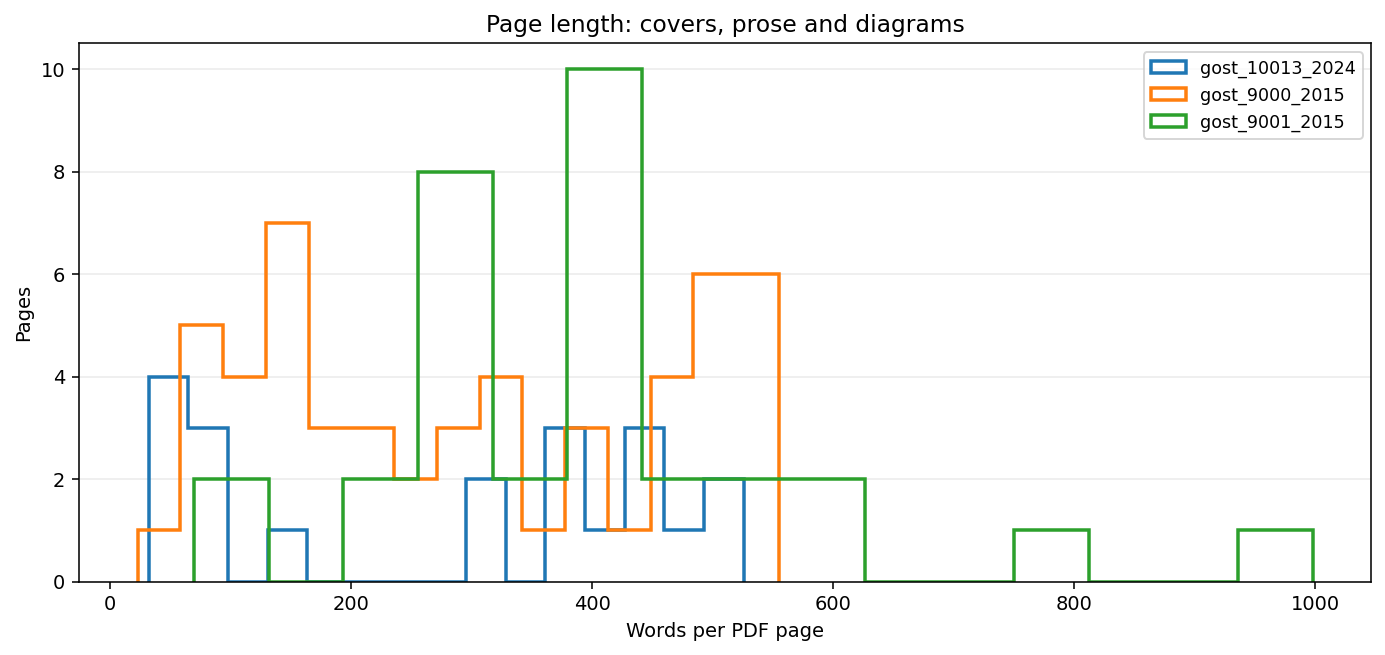

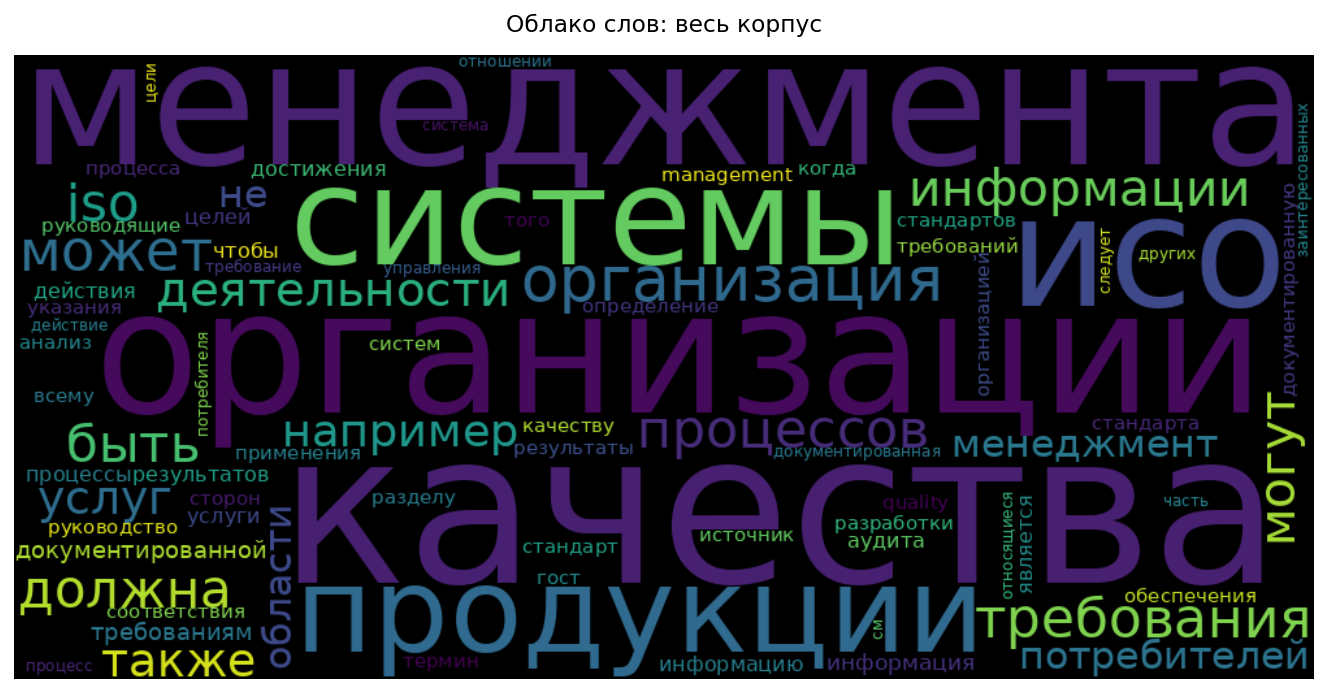

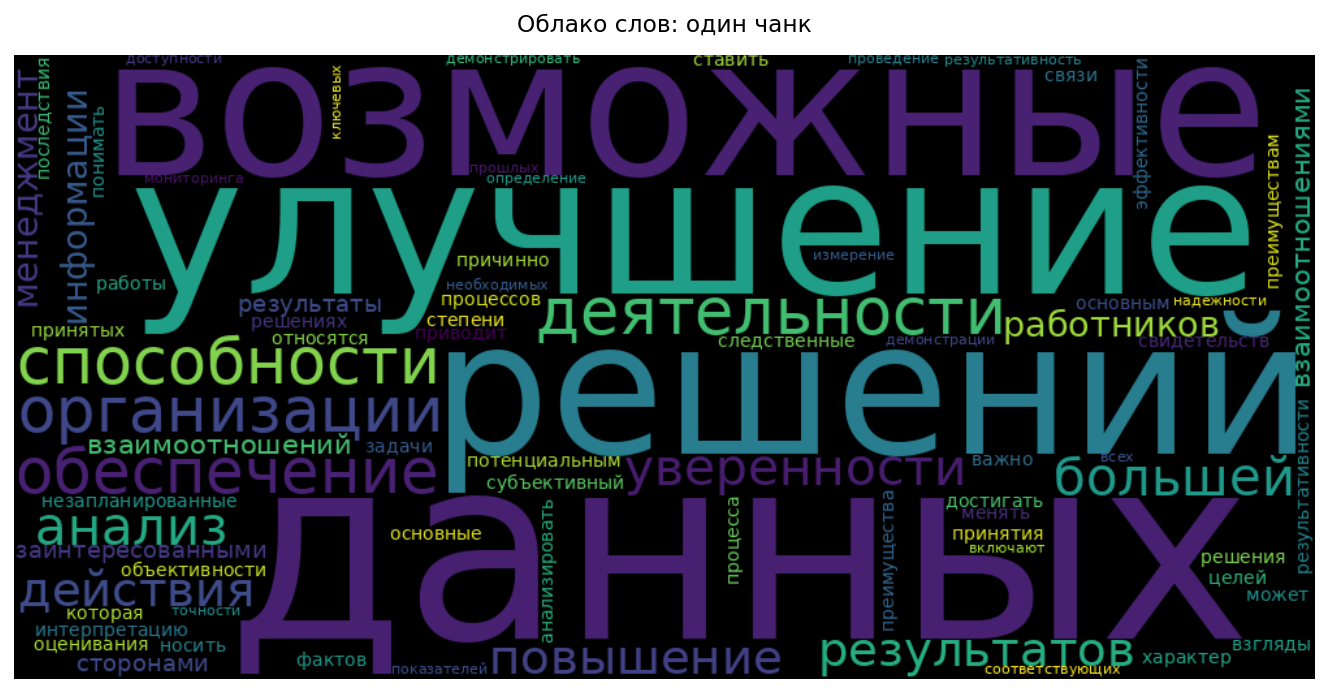

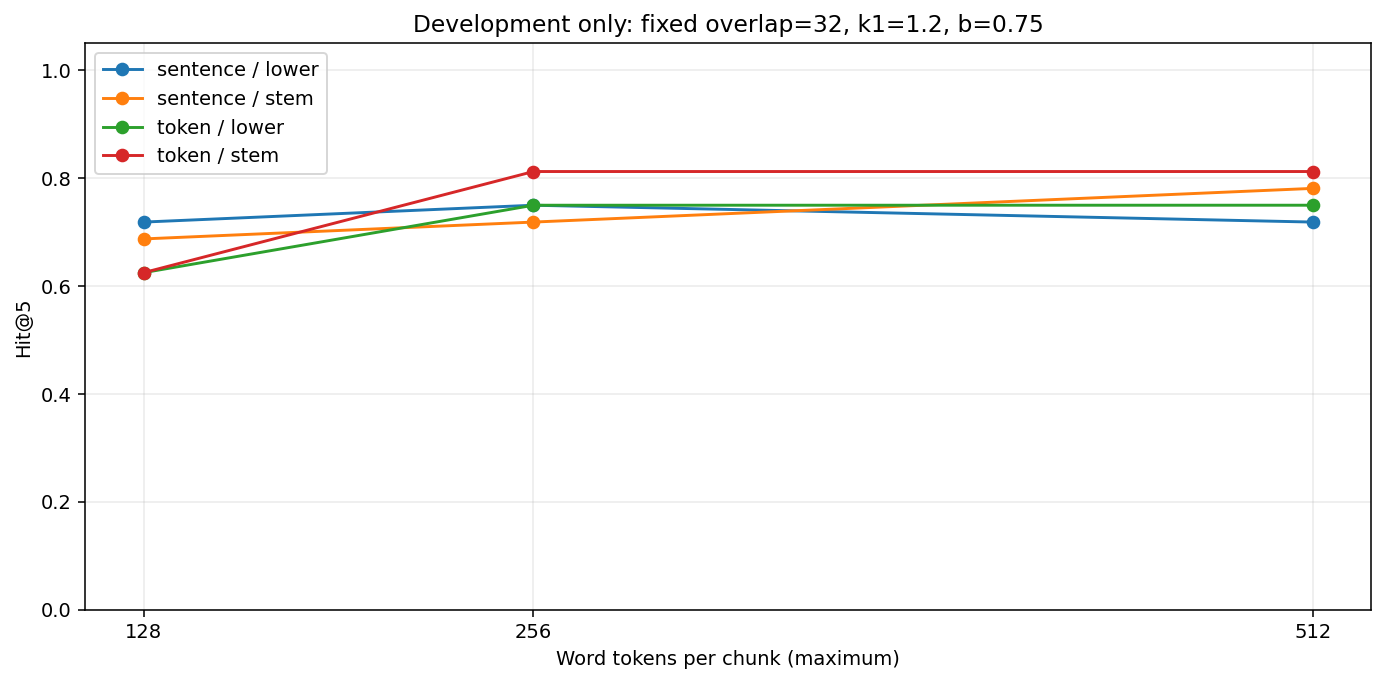

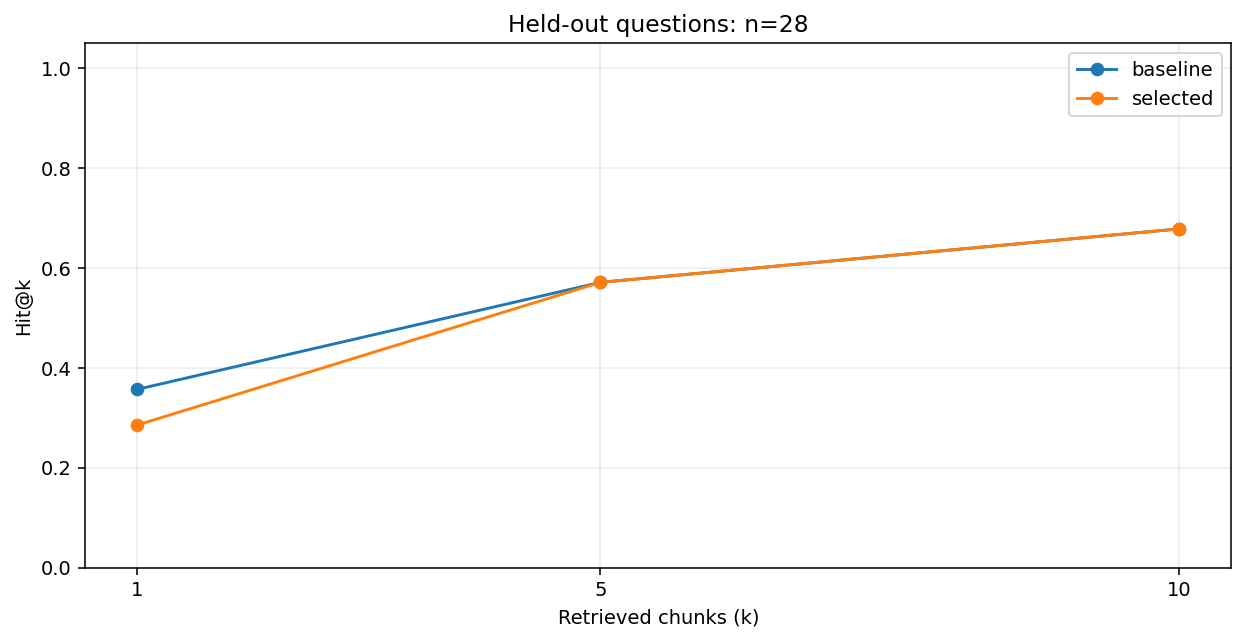

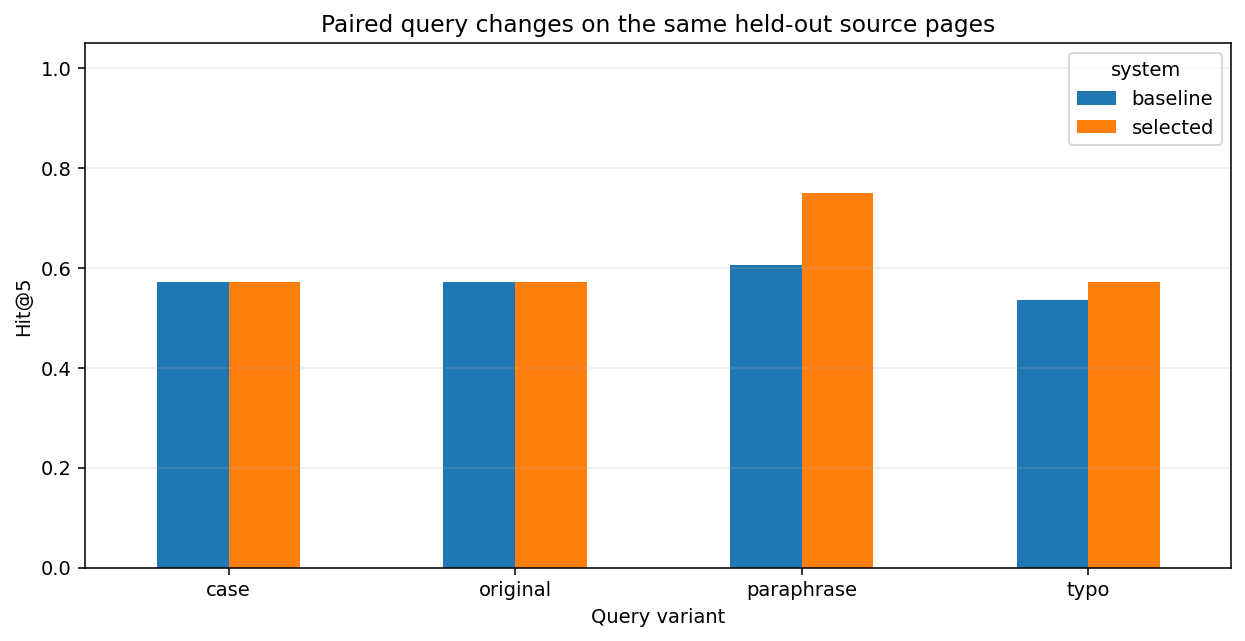

In [6]:
audit, test = build_report()
for name in ['page_lengths','corpus_cloud','chunk_cloud','development','test','augmentation']:
    display(Image(filename=str(ROOT/'figures'/f'{name}.png'),width=850))


## 6. Вывод и следующий шаг

На основных отложенных вопросах выбранные параметры не превзошли базовый вариант по Hit@5. Переформулировки и опечатки рассматриваются отдельно. Вывод о превосходстве модели на пользовательских вопросах не подтвержден. Числа, примеры пропусков и ограничения сохранены в `report.md`.

Основная логика находится в модулях Python. Следующий шаг: проверка разметки человеком и сравнение с векторным поиском на том же тесте.